<a href="https://colab.research.google.com/github/Cheikhcisse1/projet_FN/blob/main/SARIMAX_ventes_glaces_meteo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Prévision des ventes de glaces selon la météo — modèle SARIMAX

**Question :** la météo (température, jours de pluie) aide-t-elle à prévoir les ventes de glaces ?

**SARIMAX** = **SARIMA** (la série s'explique par son propre passé : tendance + saisonnalité) **+ X** (des variables **exogènes** externes, ici la météo).

$$\log(\text{ventes}_t) = \beta_1 \cdot \text{température}_t + \beta_2 \cdot \text{pluie}_t + \text{SARIMA}(p,d,q)(P,D,Q)_{12}$$

**Démarche :** chargement et alignement → exploration → stationnarité → modèles (sans / avec météo) → tests → évaluation → prévision 2026 par scénarios.

In [ ]:
# Colab : décommenter si besoin
# %pip install -q pmdarima

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True

## 1. Chargement et alignement des deux datasets

Deux pièges à gérer :
- **Dates différentes** : les ventes sont datées au **1er du mois** (`2014-01-01`), la météo au **dernier jour** (`2014-01-31`). On ramène tout au début du mois, sinon la jointure ne trouve aucune correspondance.
- **Périodes différentes** : météo 2012-2025, ventes 2014-2025 → on garde la période commune.

In [ ]:
CHEMIN_VENTES = "ventes_glaces.csv"   # Colab : "/content/ventes_glaces.csv"
CHEMIN_METEO = "meteo.csv"           # Colab : "/content/meteo.csv"

ventes = pd.read_csv(CHEMIN_VENTES, parse_dates=["date"])
meteo = pd.read_csv(CHEMIN_METEO, parse_dates=["date"])

# Ramener chaque date au 1er du mois
for df in (ventes, meteo):
    df["date"] = df["date"].dt.to_period("M").dt.to_timestamp()

ventes = ventes.set_index("date").asfreq("MS")
meteo = meteo.set_index("date").asfreq("MS")

print("Ventes :", ventes.index.min().date(), "->", ventes.index.max().date(), len(ventes), "mois")
print("Météo  :", meteo.index.min().date(), "->", meteo.index.max().date(), len(meteo), "mois")
print("\nValeurs manquantes météo :\n", meteo.isna().sum())
display(meteo[meteo.isna().any(axis=1)])

Ventes : 2014-01-01 -> 2025-12-01 144 mois
Météo  : 2012-01-01 -> 2025-12-01 168 mois

Valeurs manquantes météo :
 temperature_moy    2
jours_pluie        0
dtype: int64


,temperature_moy,jours_pluie
date,,
2015-05-01,NaN,10
2020-06-01,NaN,11


Deux températures manquent (mai 2015, juin 2020). On les **interpole** : la température évolue progressivement d'un mois à l'autre, la moyenne des mois voisins est une bonne estimation.

In [ ]:
meteo["temperature_moy"] = meteo["temperature_moy"].interpolate(method="time")

data = ventes.join(meteo, how="inner")
data["log_ventes"] = np.log(data["ventes_litres"])
print("Données fusionnées :", data.shape, "| manquants :", data.isna().sum().sum())
display(data.head())

Données fusionnées : (144, 4) | manquants : 0


,ventes_litres,temperature_moy,jours_pluie,log_ventes
date,,,,
2014-01-01,353,4.8,12,5.866468
2014-02-01,410,6.8,11,6.016157
2014-03-01,889,12.3,8,6.790097
2014-04-01,1143,12.9,9,7.041412
2014-05-01,1984,18.0,6,7.592870


## 2. Exploration

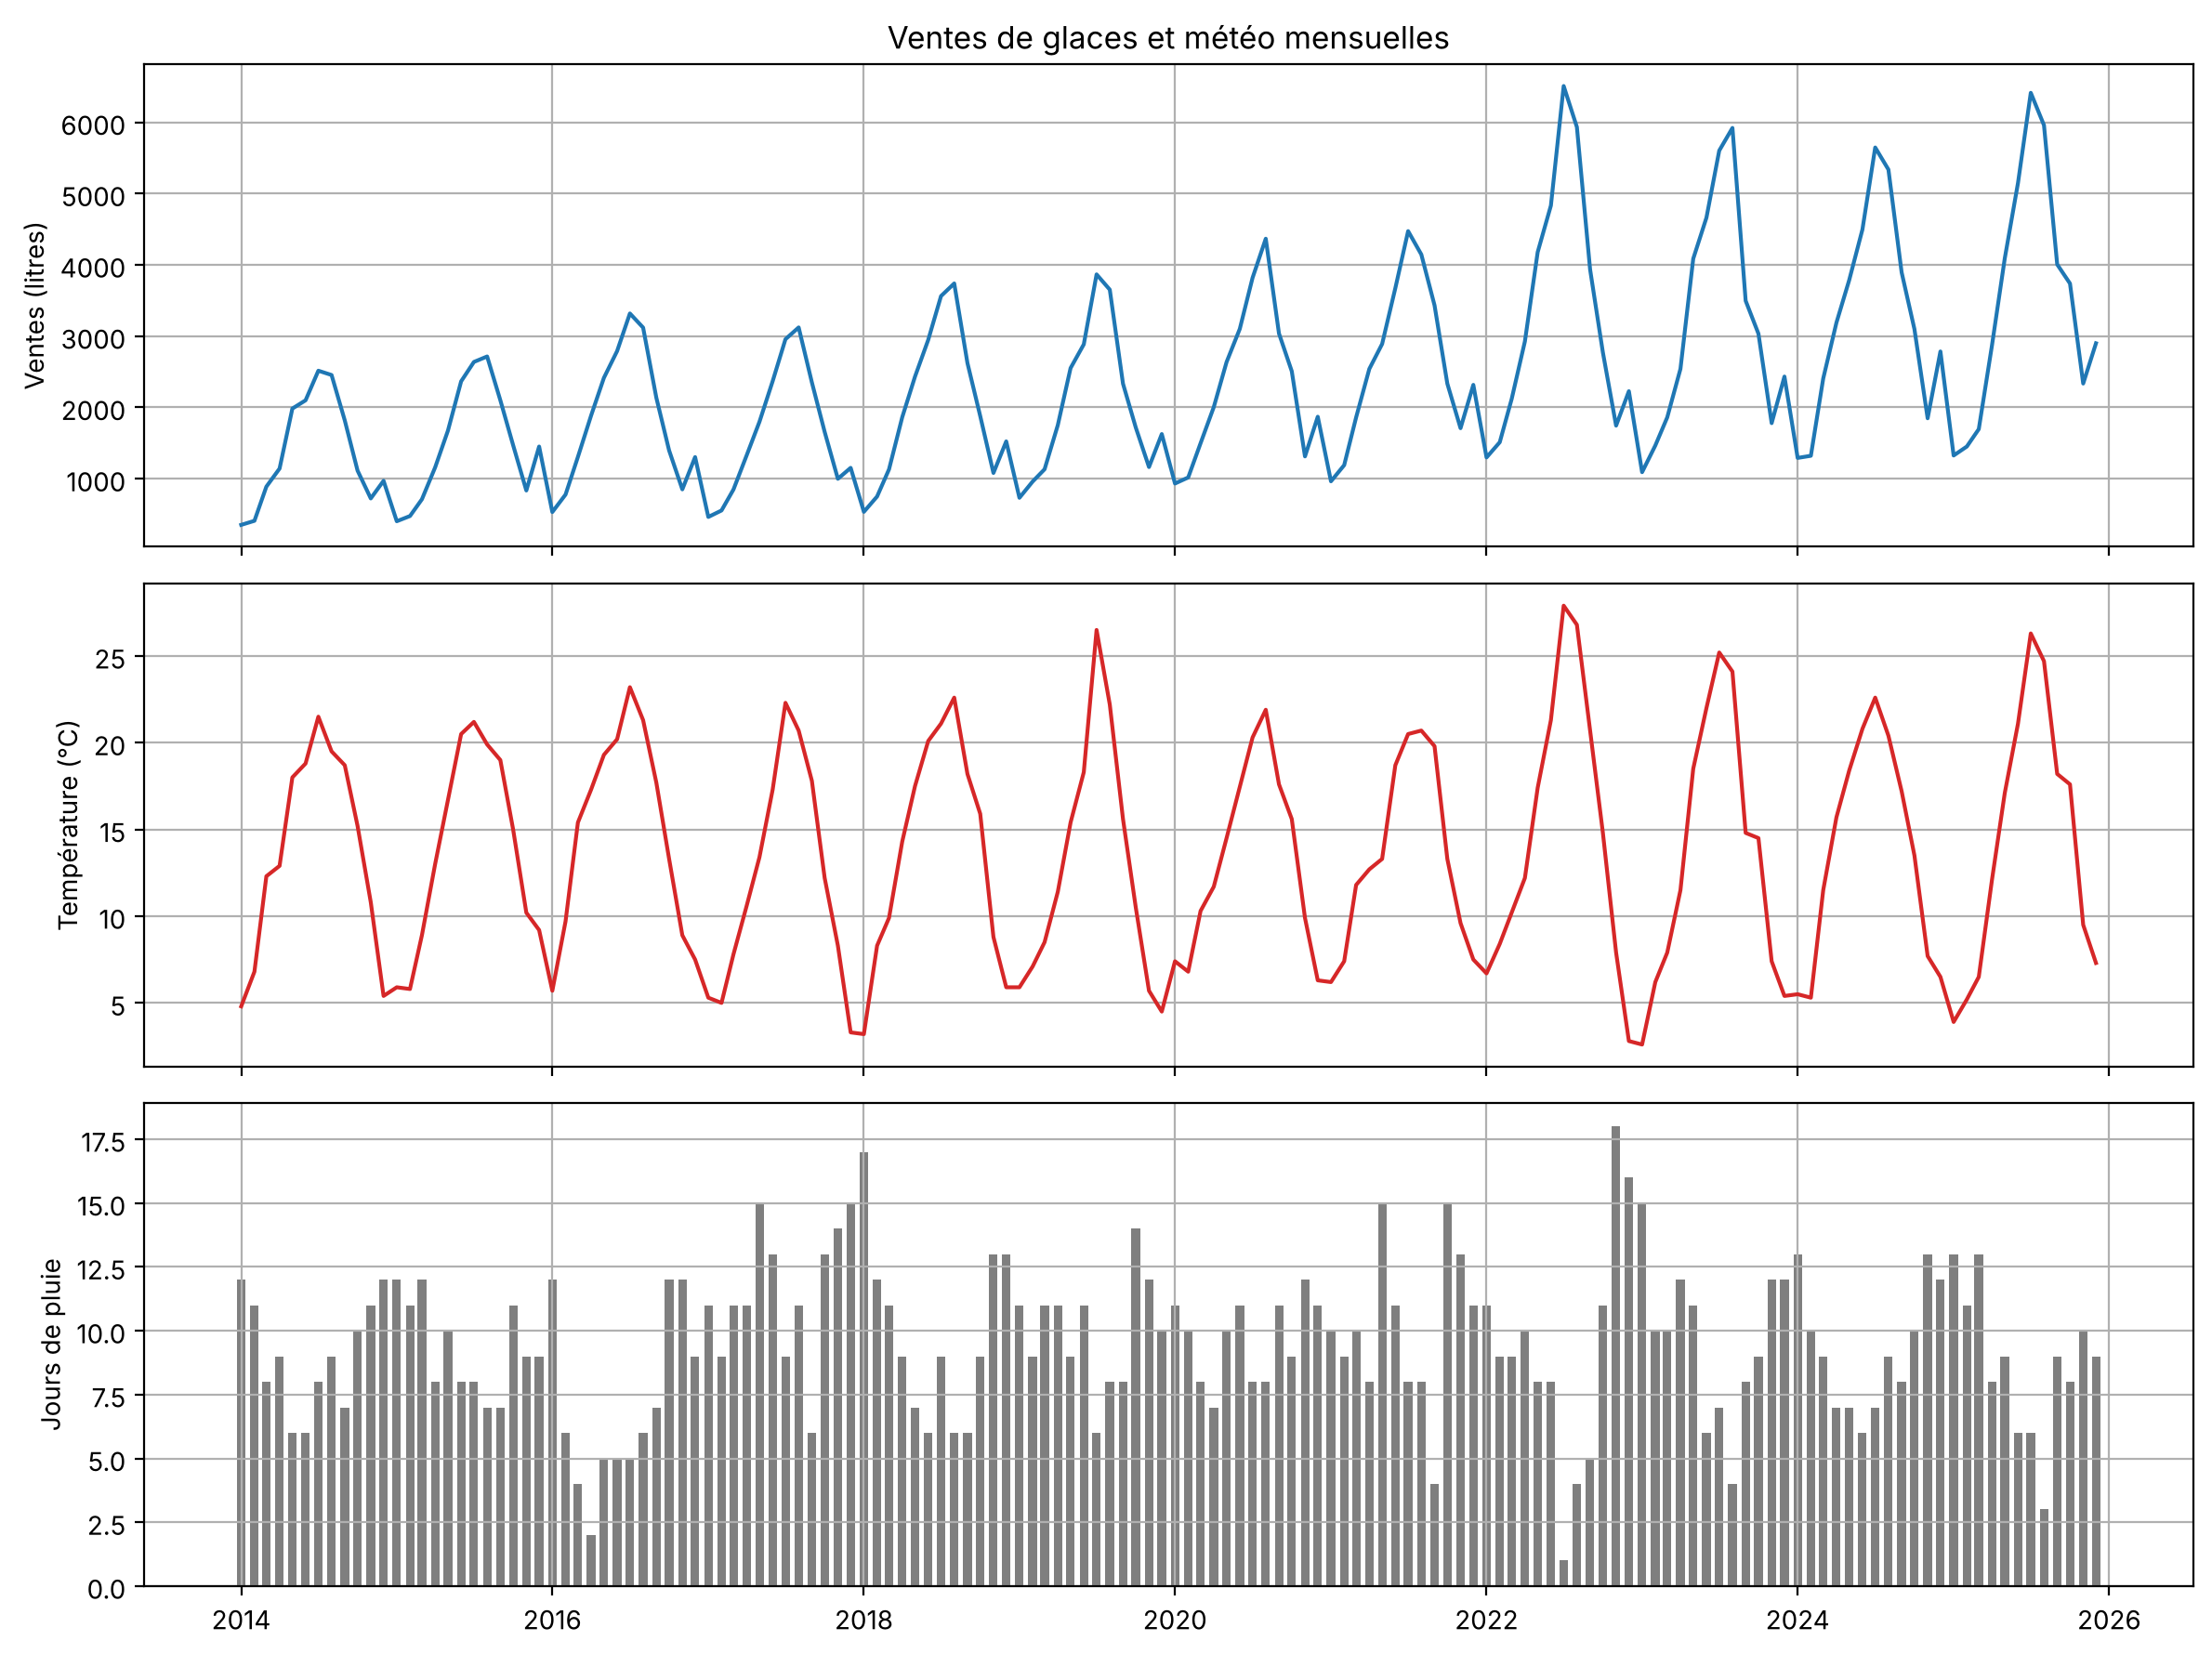

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axes[0].plot(data["ventes_litres"], color="tab:blue"); axes[0].set_ylabel("Ventes (litres)")
axes[1].plot(data["temperature_moy"], color="tab:red"); axes[1].set_ylabel("Température (°C)")
axes[2].bar(data.index, data["jours_pluie"], width=20, color="tab:gray"); axes[2].set_ylabel("Jours de pluie")
axes[0].set_title("Ventes de glaces et météo mensuelles")
plt.tight_layout(); plt.show()

**Lecture :**
- Les ventes ont une **forte saisonnalité** (pic en juillet-août) et une **tendance croissante** ; l'amplitude des pics augmente → série multiplicative → on travaille sur le **log**.
- La température suit le même rythme saisonnier ; la pluie évolue en sens inverse.
- Les étés chauds (2022, 2025) correspondent aux pics de ventes les plus élevés.

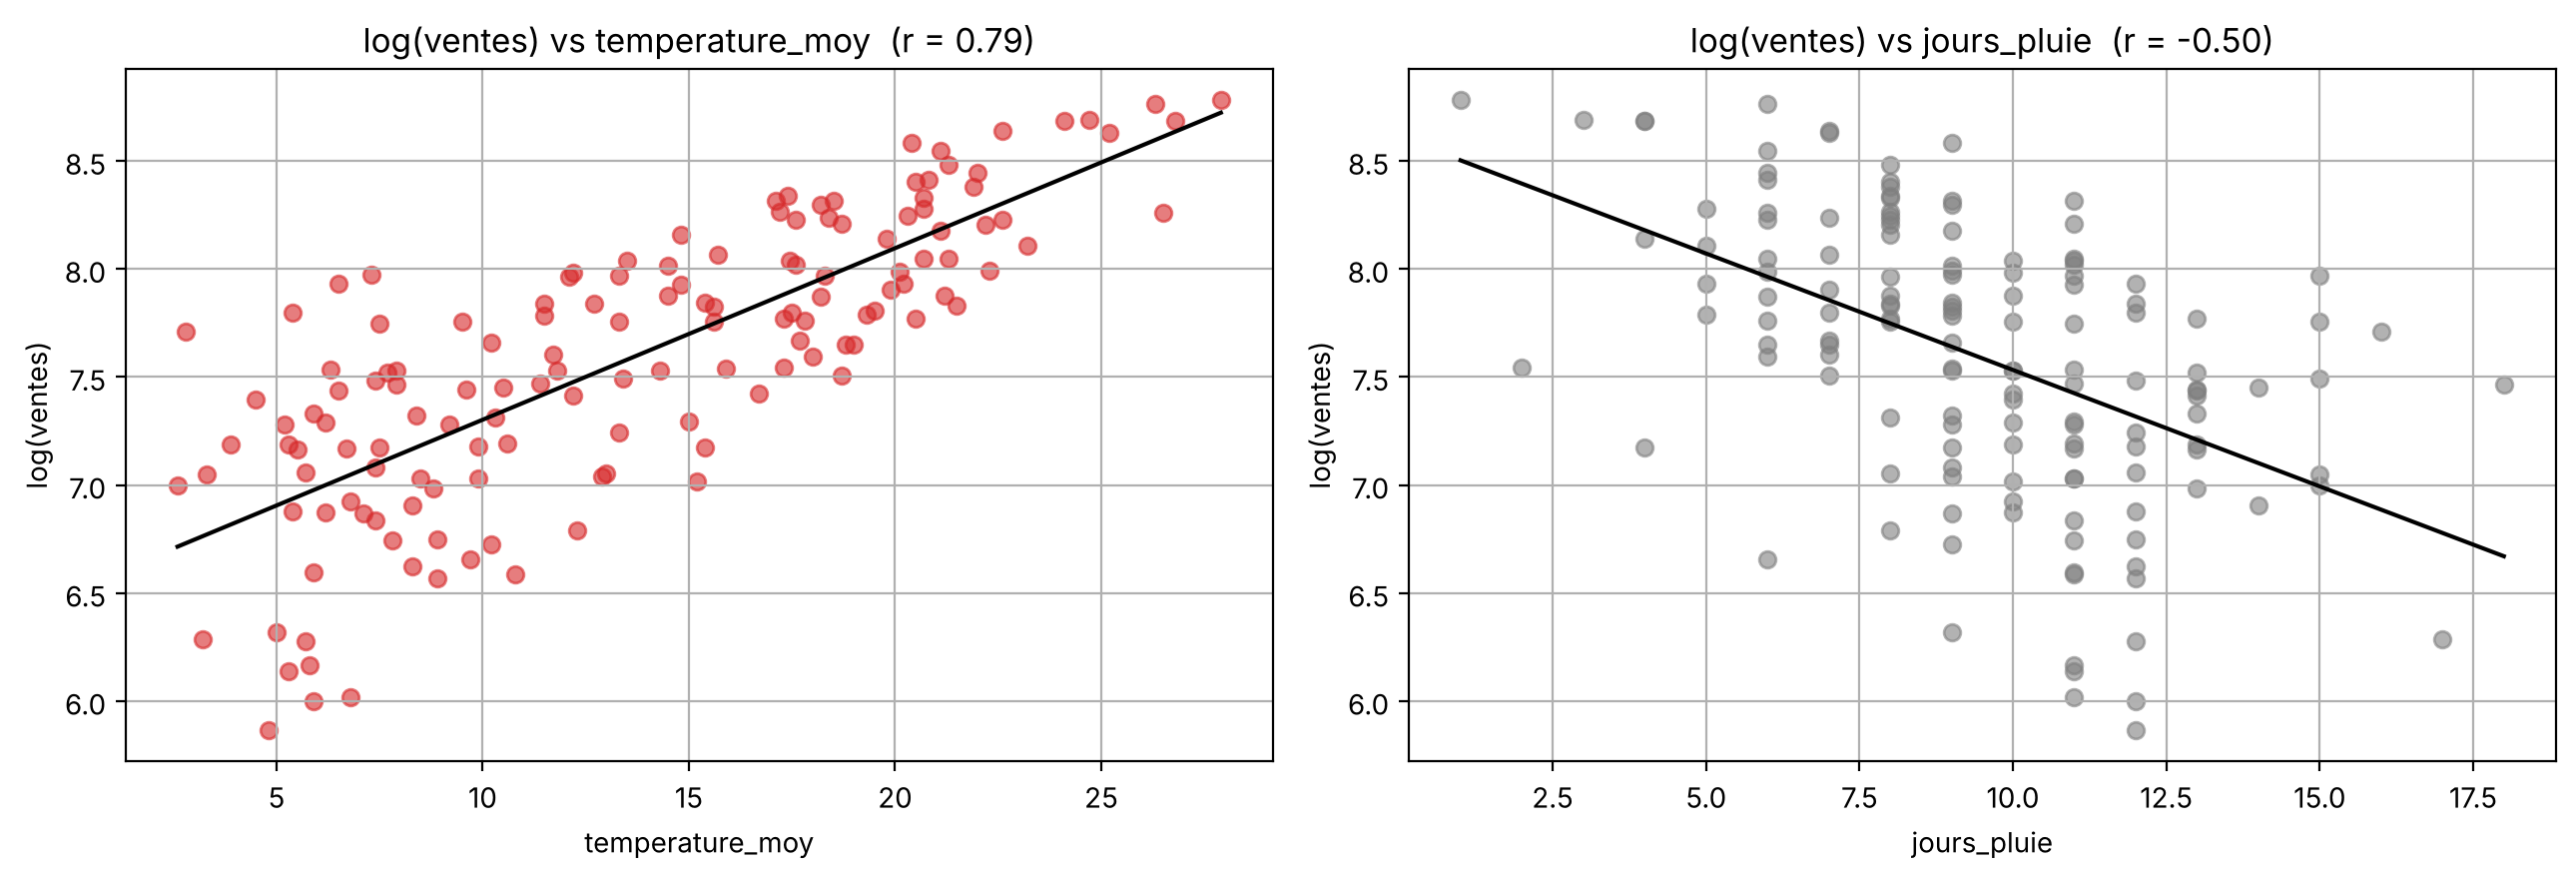

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, var, coul in zip(axes, ["temperature_moy", "jours_pluie"], ["tab:red", "tab:gray"]):
    ax.scatter(data[var], data["log_ventes"], color=coul, alpha=0.6)
    pente, origine = np.polyfit(data[var], data["log_ventes"], 1)
    xs = np.linspace(data[var].min(), data[var].max(), 50)
    ax.plot(xs, origine + pente * xs, color="black")
    ax.set_xlabel(var); ax.set_ylabel("log(ventes)")
    ax.set_title(f"log(ventes) vs {var}  (r = {data[var].corr(data['log_ventes']):.2f})")
plt.tight_layout(); plt.show()

### Attention à la corrélation « gonflée » par la saisonnalité

Température et ventes montent toutes les deux en été : une partie de leur corrélation vient seulement du **calendrier**. Pour mesurer le vrai lien, on compare les **anomalies** : l'écart de chaque mois à la moyenne de ce mois (ex. juillet 2022 par rapport à un juillet moyen).

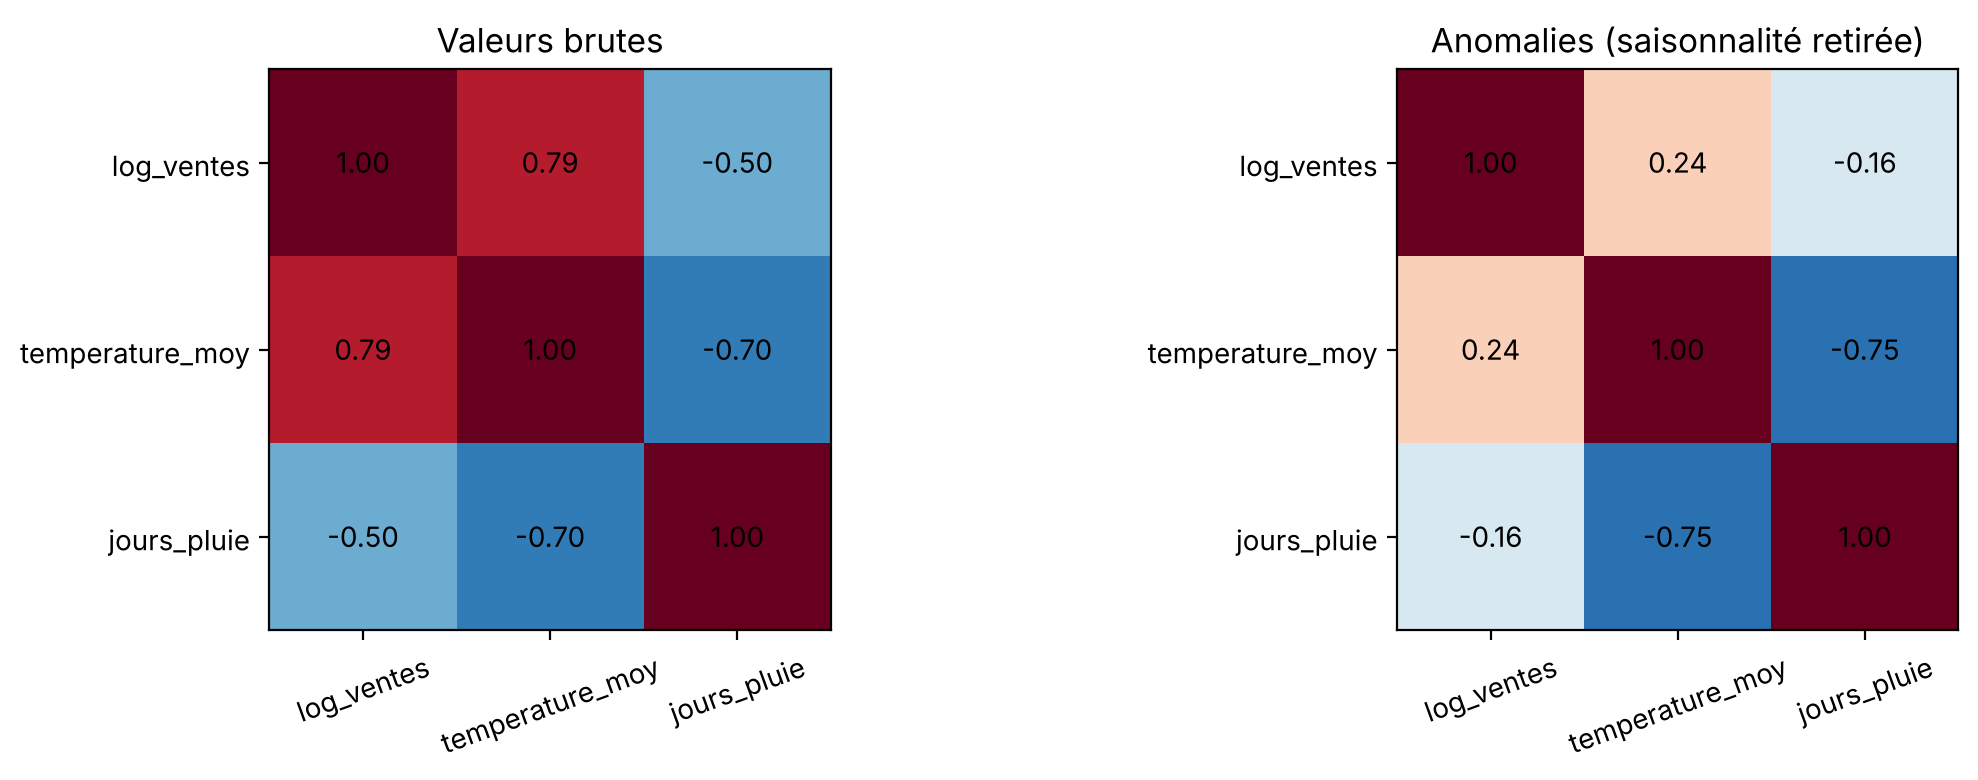

In [ ]:
cols = ["log_ventes", "temperature_moy", "jours_pluie"]
anomalies = data[cols] - data[cols].groupby(data.index.month).transform("mean")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, df, titre in zip(axes, [data[cols], anomalies], ["Valeurs brutes", "Anomalies (saisonnalité retirée)"]):
    corr = df.corr()
    im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(3)); ax.set_yticks(range(3))
    ax.set_xticklabels(cols, rotation=20); ax.set_yticklabels(cols)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
    ax.set_title(titre); ax.grid(False)
plt.tight_layout(); plt.show()

**Lecture :**
- En brut, température ↔ ventes ≈ 0,8 : très fort, mais en grande partie dû à la saison commune.
- En anomalies, le lien est plus modéré (≈ 0,24) mais reste **positif** : un mois plus chaud que la normale fait vendre plus que la normale. C'est cette information que SARIMAX va exploiter, puisque la partie SARIMA s'occupe déjà de la saisonnalité.
- Température et pluie sont **fortement corrélées entre elles** (≈ -0,7) : elles portent en partie la même information (colinéarité). Il est probable qu'une seule des deux suffise.

## 3. Stationnarité et identification

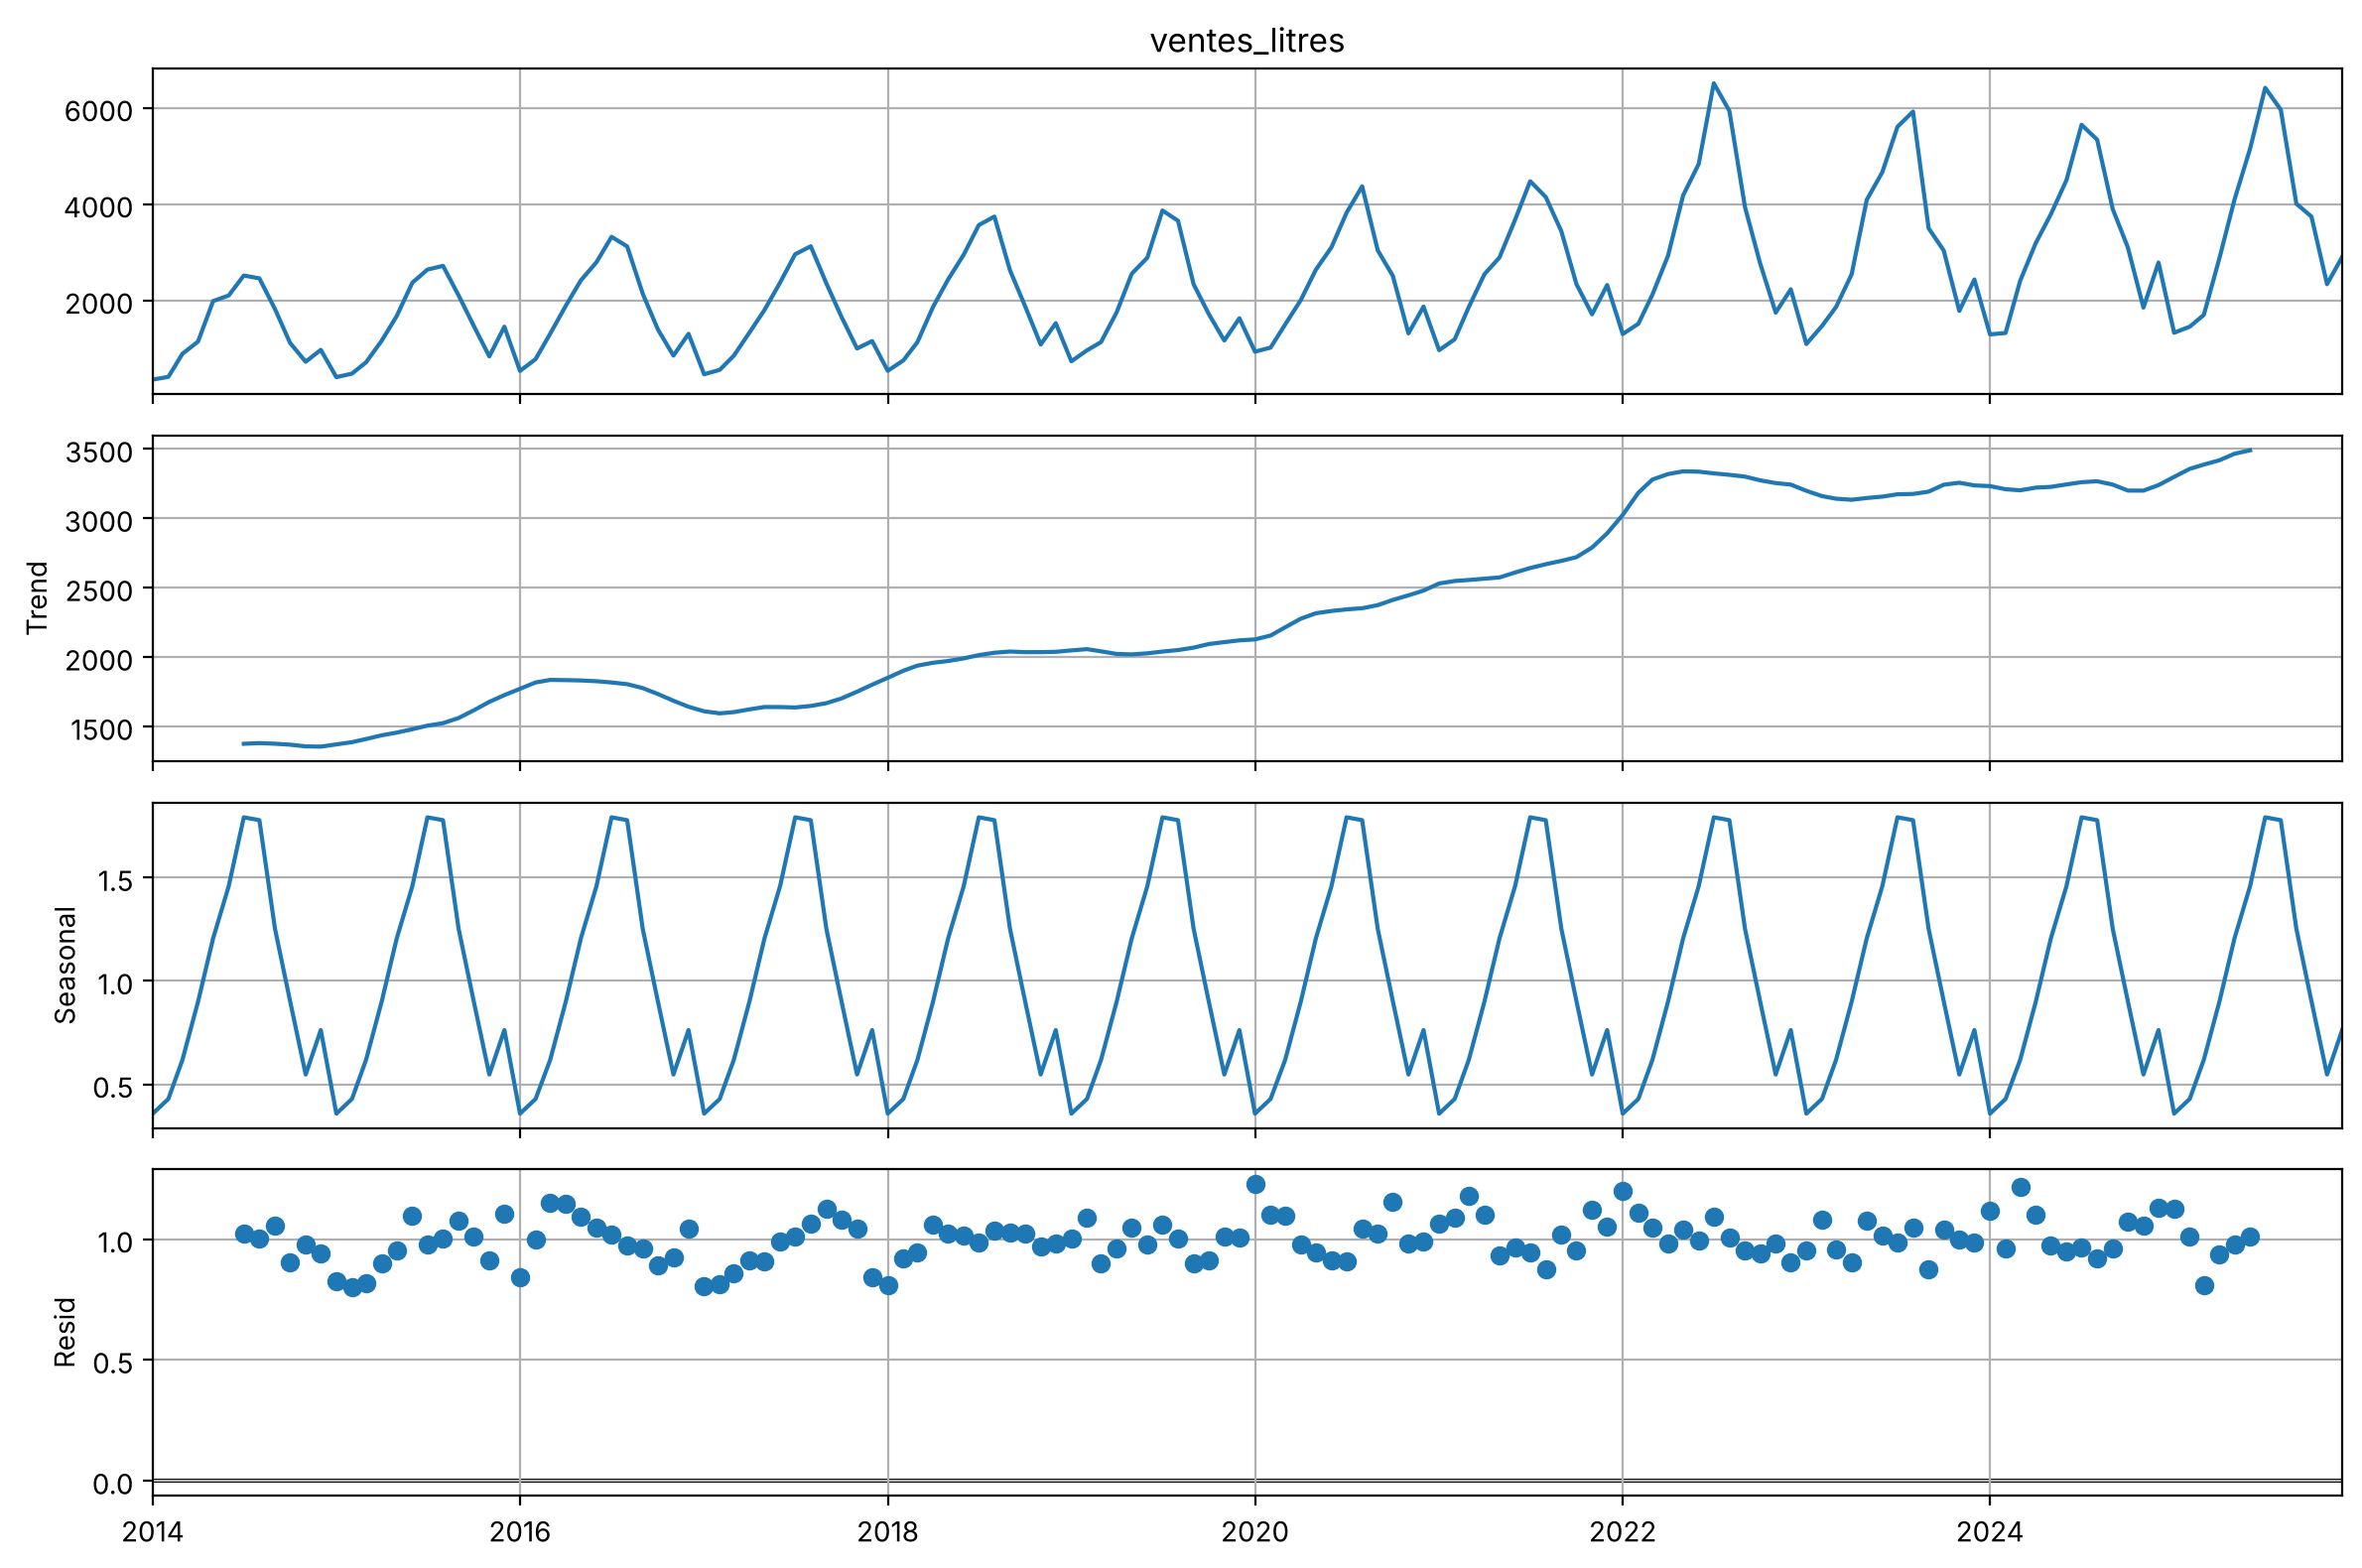

log(ventes)                         ADF p = 0.7408 | KPSS p = 0.0100 -> NON stationnaire / douteux
log(ventes) + d=1 + D=1 (12)        ADF p = 0.0000 | KPSS p = 0.1000 -> STATIONNAIRE


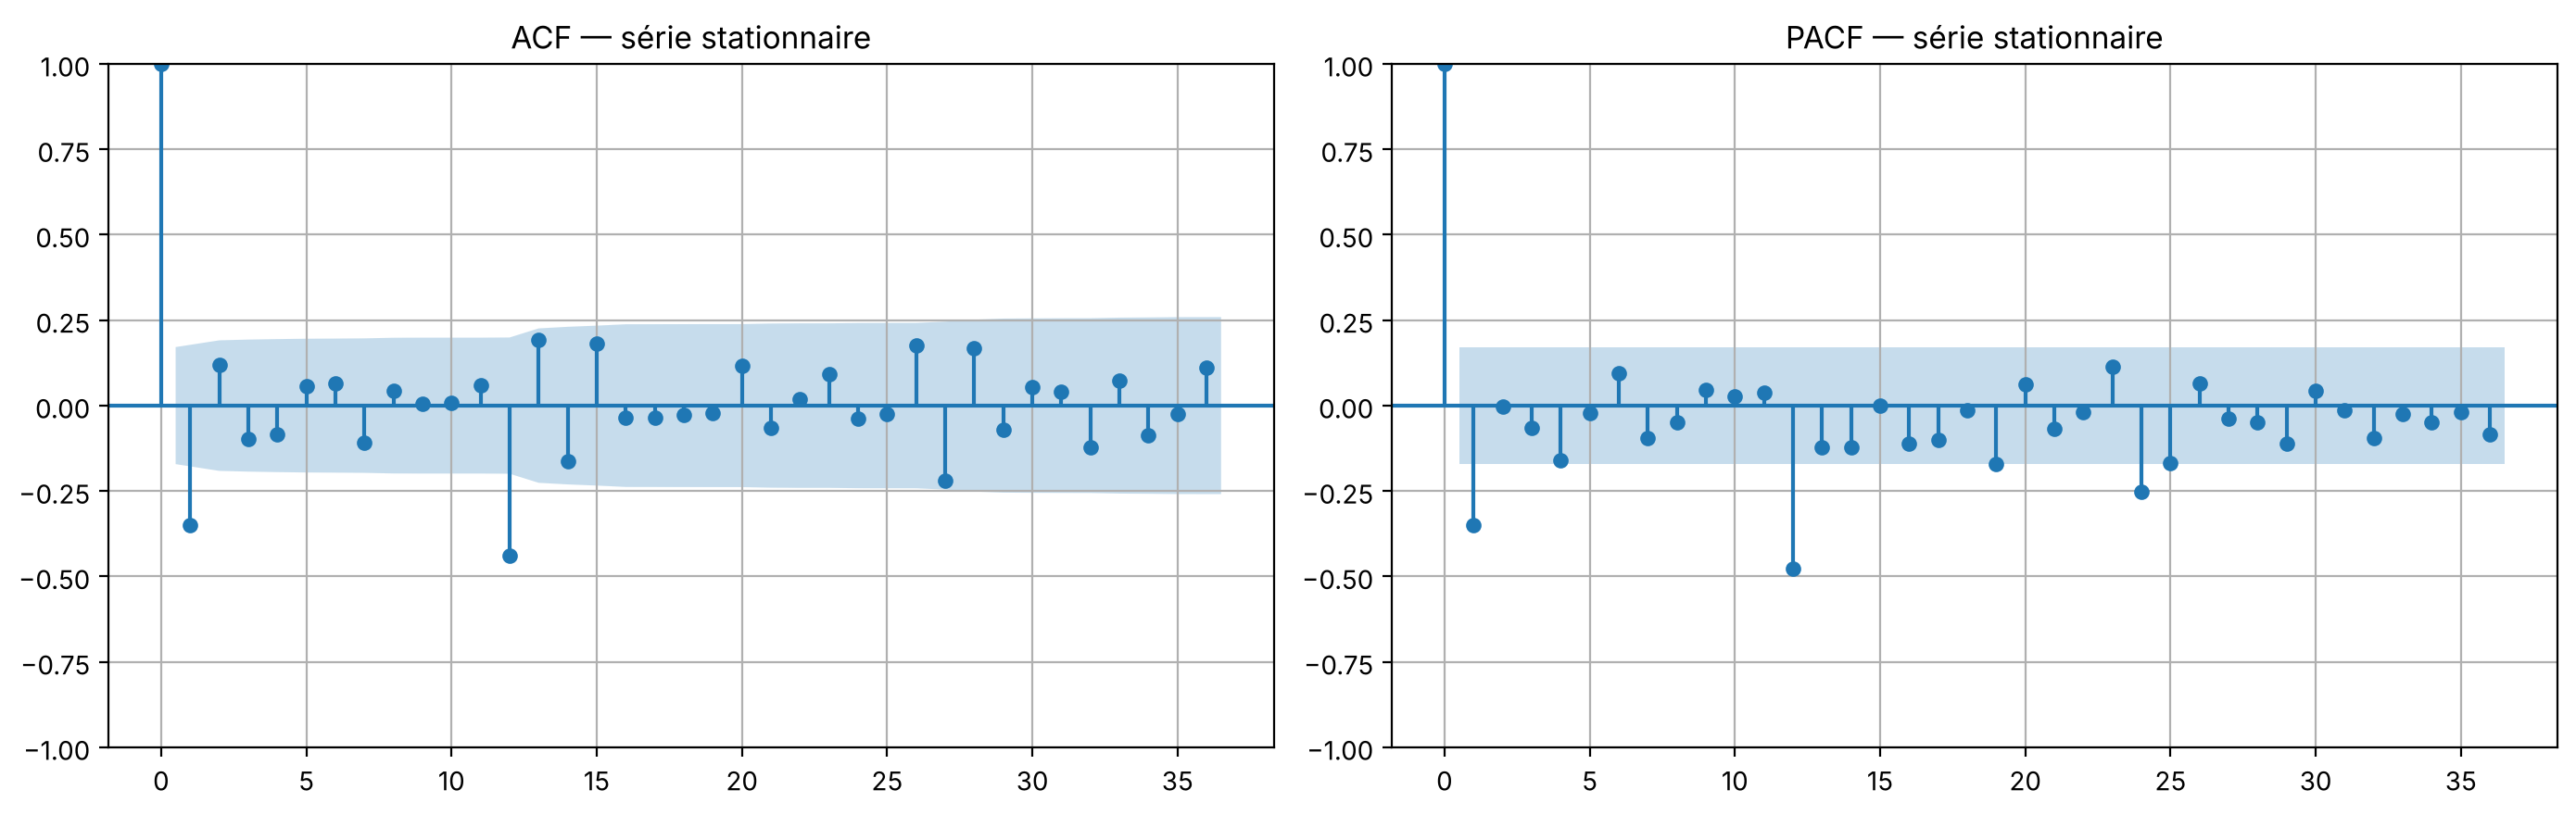

In [ ]:
decomp = seasonal_decompose(data["ventes_litres"], model="multiplicative", period=12)
fig = decomp.plot(); fig.set_size_inches(12, 8); plt.tight_layout(); plt.show()

def stationnarite(serie, nom):
    serie = serie.dropna()
    p_adf = adfuller(serie)[1]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        p_kpss = kpss(serie, regression="c", nlags="auto")[1]
    verdict = "STATIONNAIRE" if (p_adf < 0.05 and p_kpss > 0.05) else "NON stationnaire / douteux"
    print(f"{nom:<35} ADF p = {p_adf:.4f} | KPSS p = {p_kpss:.4f} -> {verdict}")

serie_stat = data["log_ventes"].diff().diff(12)
stationnarite(data["log_ventes"], "log(ventes)")
stationnarite(serie_stat, "log(ventes) + d=1 + D=1 (12)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
plot_acf(serie_stat.dropna(), lags=36, ax=axes[0]); axes[0].set_title("ACF — série stationnaire")
plot_pacf(serie_stat.dropna(), lags=36, ax=axes[1], method="ywm"); axes[1].set_title("PACF — série stationnaire")
plt.tight_layout(); plt.show()

**Lecture :** après log + différenciation simple + saisonnière, la série est stationnaire. L'ACF montre un pic négatif au retard **1** et au retard **12**, puis plus rien → **MA(1)** et **MA(1) saisonnier**.

Modèle de base : **SARIMA(0,1,1)(0,1,1)[12]** sur log(ventes). On va lui ajouter la météo.

## 4. Modélisation

On garde les **24 derniers mois (2024-2025) comme jeu de test**. Pour ces mois, on fournit au modèle la **météo réellement observée** : on mesure ainsi ce que la météo apporte à la prévision.

In [ ]:
ORDER, SEASONAL = (0, 1, 1), (0, 1, 1, 12)
N_TEST = 24
train, test = data.iloc[:-N_TEST], data.iloc[-N_TEST:]
print(f"Entraînement : {train.index[0].date()} -> {train.index[-1].date()} ({len(train)} mois)")
print(f"Test         : {test.index[0].date()} -> {test.index[-1].date()} ({len(test)} mois)")

configurations = {
    "SARIMA (sans météo)": None,
    "SARIMAX + température": ["temperature_moy"],
    "SARIMAX + pluie": ["jours_pluie"],
    "SARIMAX + température + pluie": ["temperature_moy", "jours_pluie"],
}

modeles, previsions, lignes = {}, {}, []
for nom, exog in configurations.items():
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        res = SARIMAX(train["log_ventes"], exog=train[exog] if exog else None,
                      order=ORDER, seasonal_order=SEASONAL).fit(disp=False)
    f = res.get_forecast(N_TEST, exog=test[exog] if exog else None)
    ci = f.conf_int()
    prev = pd.DataFrame({"prevision": np.exp(f.predicted_mean),
                         "borne_inf": np.exp(ci.iloc[:, 0]),
                         "borne_sup": np.exp(ci.iloc[:, 1])})
    e = test["ventes_litres"] - prev["prevision"]
    modeles[nom], previsions[nom] = res, prev
    lignes.append({"modèle": nom, "AIC": res.aic, "BIC": res.bic,
                   "MAE": e.abs().mean(), "RMSE": np.sqrt((e ** 2).mean()),
                   "MAPE (%)": (e.abs() / test["ventes_litres"]).mean() * 100})

comparaison = pd.DataFrame(lignes).set_index("modèle").round(2)
display(comparaison)

Entraînement : 2014-01-01 -> 2023-12-01 (120 mois)
Test         : 2024-01-01 -> 2025-12-01 (24 mois)


,AIC,BIC,MAE,RMSE,MAPE (%)
modèle,,,,,
SARIMA (sans météo),-159.51,-151.49,327.20,397.88,9.99
SARIMAX + température,-235.75,-225.06,225.40,316.18,6.62
SARIMAX + pluie,-196.36,-185.67,222.91,298.20,7.16
SARIMAX + température + pluie,-236.53,-223.17,206.21,290.20,6.20


**Comment comparer :**
- **AIC / BIC** (sur l'entraînement) : plus petit = meilleur compromis ajustement / simplicité.
- **MAE, RMSE, MAPE** (sur le test) : erreurs de prévision ; la MAPE est en %.

On retient le modèle qui améliore nettement ces critères **et** dont les coefficients sont significatifs (section suivante).

## 5. Interprétation des coefficients météo

In [ ]:
for nom in ["SARIMAX + température", "SARIMAX + pluie", "SARIMAX + température + pluie"]:
    res = modeles[nom]
    print(f"===== {nom} =====")
    for var in [v for v in ["temperature_moy", "jours_pluie"] if v in res.params]:
        b, p = res.params[var], res.pvalues[var]
        effet = (np.exp(b) - 1) * 100
        unite = "+1 °C" if var == "temperature_moy" else "+1 jour de pluie"
        print(f"  {var:<16} coef = {b:+.4f} | p-value = {p:.4f} "
              f"({'significatif' if p < 0.05 else 'NON significatif'}) -> {unite} = {effet:+.1f} % de ventes")
    print()

===== SARIMAX + température =====
  temperature_moy  coef = +0.0385 | p-value = 0.0000 (significatif) -> +1 °C = +3.9 % de ventes

===== SARIMAX + pluie =====
  jours_pluie      coef = -0.0226 | p-value = 0.0000 (significatif) -> +1 jour de pluie = -2.2 % de ventes

===== SARIMAX + température + pluie =====
  temperature_moy  coef = +0.0334 | p-value = 0.0000 (significatif) -> +1 °C = +3.4 % de ventes
  jours_pluie      coef = -0.0058 | p-value = 0.1408 (NON significatif) -> +1 jour de pluie = -0.6 % de ventes



**Lecture :**
- Comme le modèle porte sur **log(ventes)**, un coefficient β s'interprète en pourcentage : **effet = (e^β − 1) × 100 %**.
- La **température** est très significative : à saison et tendance égales, **chaque degré supplémentaire augmente les ventes d'environ 4 %**.
- La **pluie** a l'effet attendu (négatif) quand elle est seule, mais devient **non significative** quand on ajoute la température : la pluie n'apporte pas d'information en plus de la température (colinéarité).

**→ Modèle retenu : SARIMAX(0,1,1)(0,1,1)[12] + température** (le plus simple parmi les meilleurs).

## 6. Validation du modèle retenu

                                     SARIMAX Results                                      
Dep. Variable:                         log_ventes   No. Observations:                  120
Model:             SARIMAX(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood                 121.876
Date:                            Tue, 10 Nov 2026   AIC                           -235.751
Time:                                    12:07:22   BIC                           -225.060
Sample:                                01-01-2014   HQIC                          -231.417
                                     - 12-01-2023                                         
Covariance Type:                              opg                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
temperature_moy     0.0385      0.004      9.725      0.000       0.031       0.046
ma.L1              -

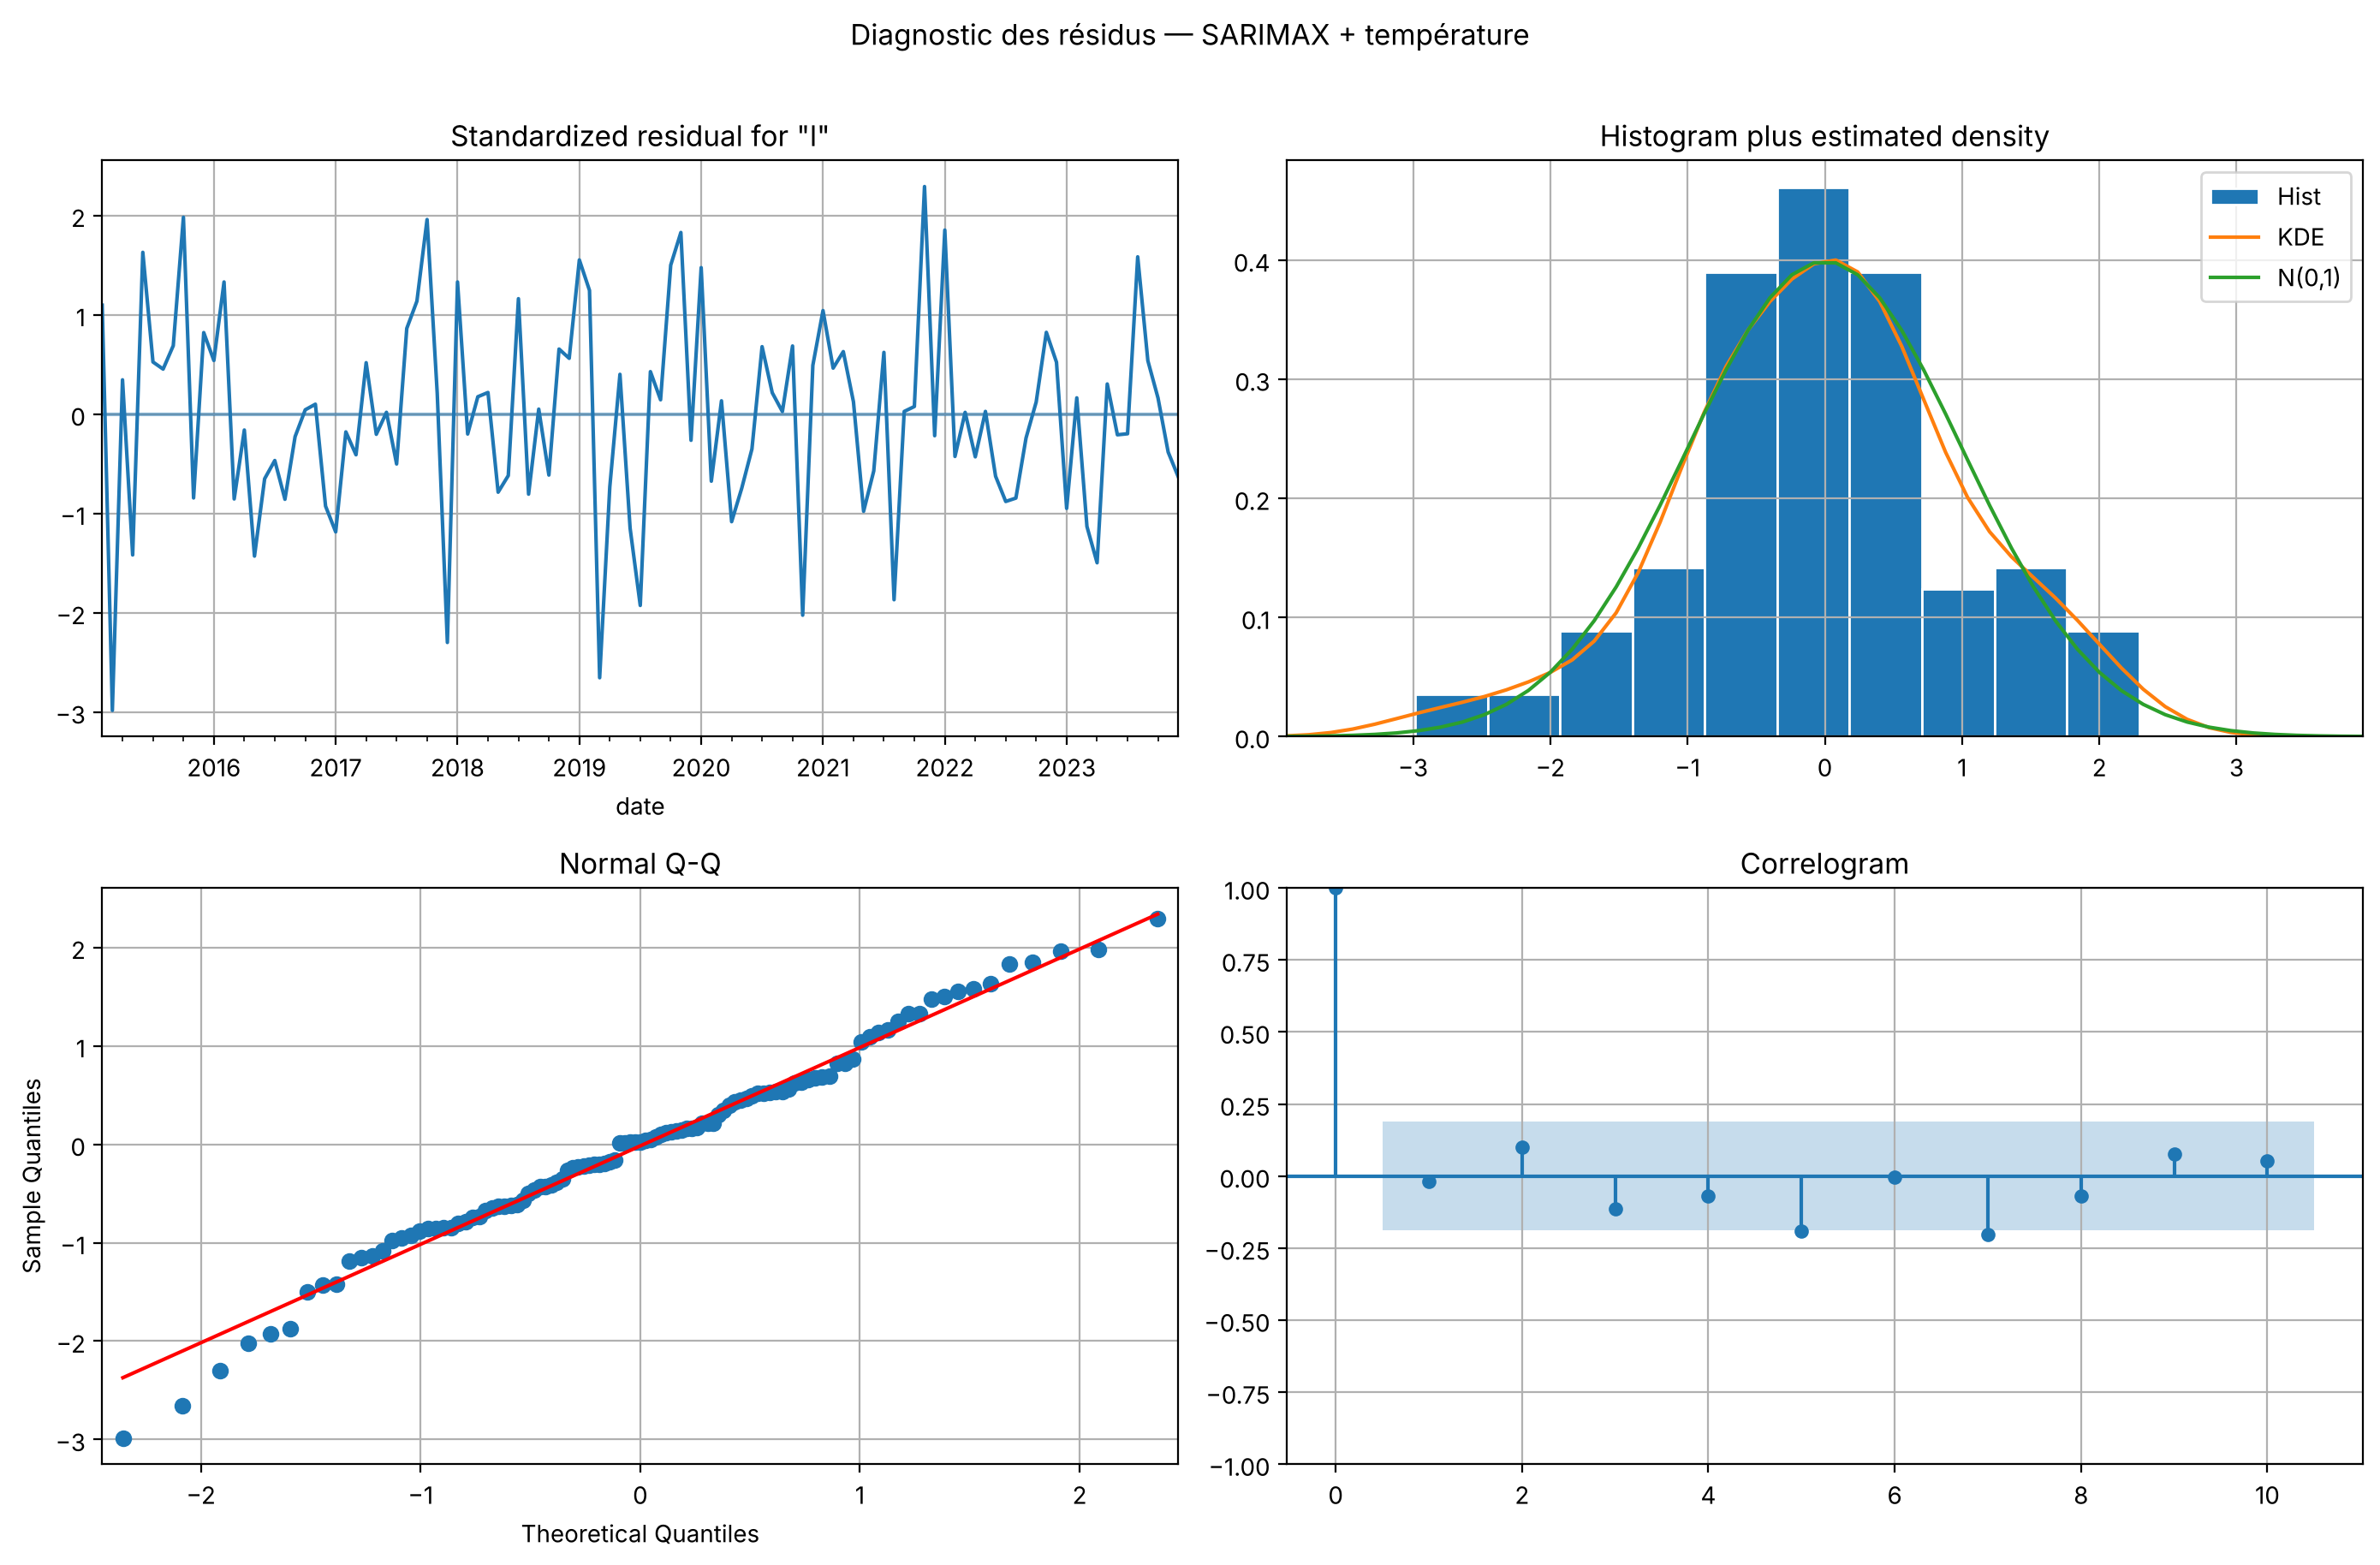

In [ ]:
RETENU = "SARIMAX + température"

def tests_parametriques(res, s=12, alpha=0.05, lags=12):
    d, D = res.model.order[1], res.model.seasonal_order[1]
    resid = pd.Series(res.resid).iloc[d + D * s:]
    ok = lambda c: "OK" if c else "ÉCHEC"
    tab = pd.DataFrame({"coef": res.params, "z": res.tvalues, "p-value": res.pvalues}).drop(index="sigma2")
    tab["significatif"] = np.where(tab["p-value"] < alpha, "oui", "NON")
    print("1. Significativité des coefficients (on veut p < 0.05)")
    print(tab.round(4).to_string(), "\n")
    p = stats.ttest_1samp(resid, 0).pvalue
    print(f"2. Moyenne des résidus = 0 (Student)    p = {p:.4f}  {ok(p > alpha)}")
    p = acorr_ljungbox(resid, lags=[lags], return_df=True)["lb_pvalue"].iloc[0]
    print(f"3. Bruit blanc (Ljung-Box, {lags} retards)  p = {p:.4f}  {ok(p > alpha)}")
    p1, p2 = stats.shapiro(resid).pvalue, stats.jarque_bera(resid).pvalue
    print(f"4. Normalité (Shapiro / Jarque-Bera)    p = {p1:.4f} / {p2:.4f}  {ok(min(p1, p2) > alpha)}")
    p = het_arch(resid, nlags=lags)[1]
    print(f"5. Variance constante (ARCH)            p = {p:.4f}  {ok(p > alpha)}")

print(modeles[RETENU].summary())
tests_parametriques(modeles[RETENU])
modeles[RETENU].plot_diagnostics(figsize=(14, 9))
plt.suptitle(f"Diagnostic des résidus — {RETENU}", y=1.01); plt.tight_layout(); plt.show()

**Lecture :** coefficients significatifs, résidus centrés, non autocorrélés (Ljung-Box), normaux et de variance stable → le modèle est **valide**.

## 7. Prévisions sur le jeu de test : avec ou sans météo

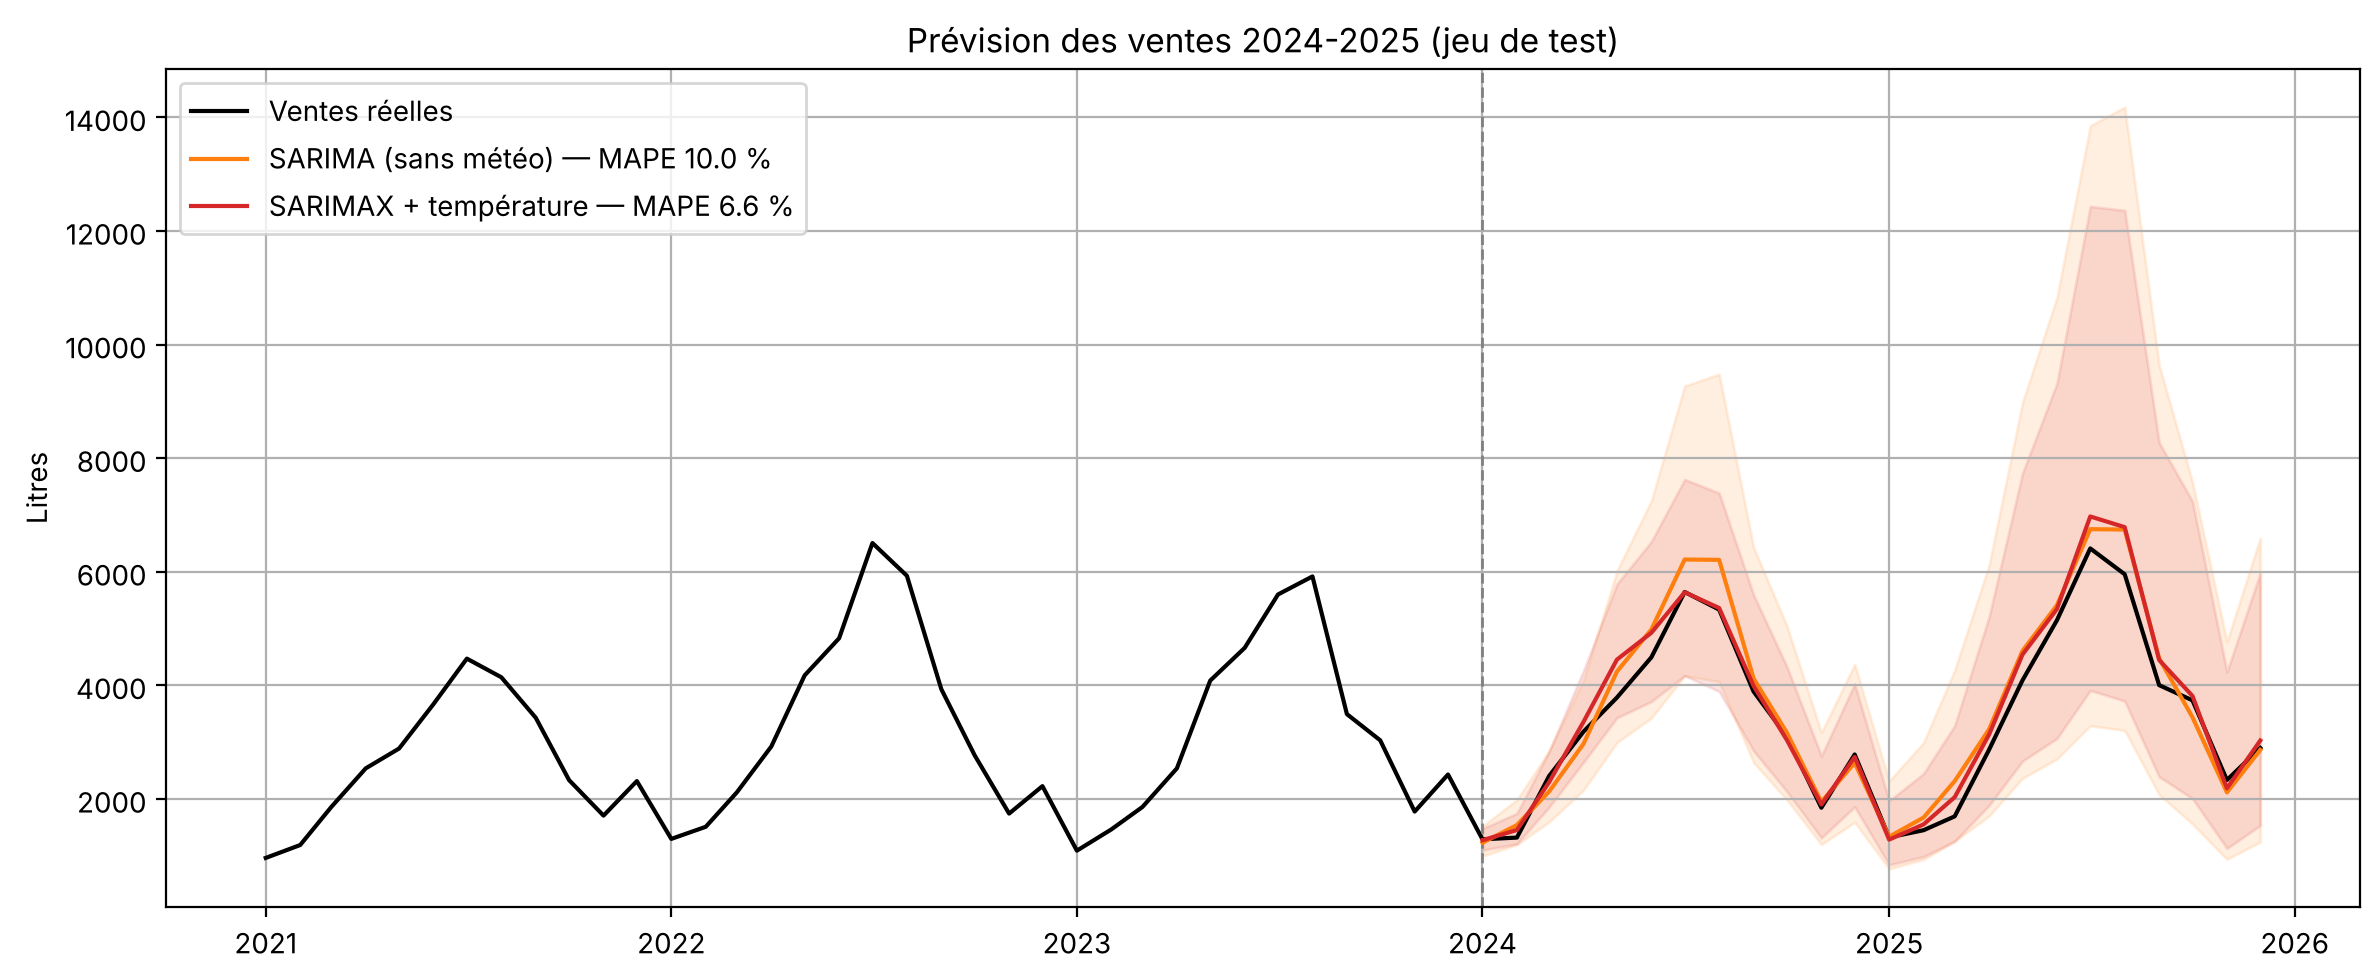

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(data["ventes_litres"]["2021":], color="black", label="Ventes réelles")
plt.axvline(test.index[0], color="grey", ls="--", lw=1)
for nom, coul in [("SARIMA (sans météo)", "tab:orange"), (RETENU, "tab:red")]:
    p = previsions[nom]
    mape = comparaison.loc[nom, "MAPE (%)"]
    plt.plot(p["prevision"], color=coul, label=f"{nom} — MAPE {mape:.1f} %")
    plt.fill_between(p.index, p["borne_inf"], p["borne_sup"], color=coul, alpha=0.12)
plt.title("Prévision des ventes 2024-2025 (jeu de test)")
plt.ylabel("Litres"); plt.legend(loc="upper left"); plt.tight_layout(); plt.show()

**Lecture :** sans météo, le modèle prévoit un « été moyen » chaque année. Avec la température, il suit mieux les variations réelles (été plus ou moins chaud), et son intervalle de confiance est **plus étroit** : la météo réduit l'incertitude.

## 8. Prévision 2026 par scénarios météo

Pour prévoir le futur avec SARIMAX, il faut **connaître la météo future** : c'est la principale limite des modèles avec variables exogènes. En pratique on utilise des prévisions météo ou des **scénarios** :
- **Normal** : température moyenne de chaque mois sur 2014-2025 ;
- **Été chaud** : +3 °C de juin à août ;
- **Été frais** : −3 °C de juin à août.

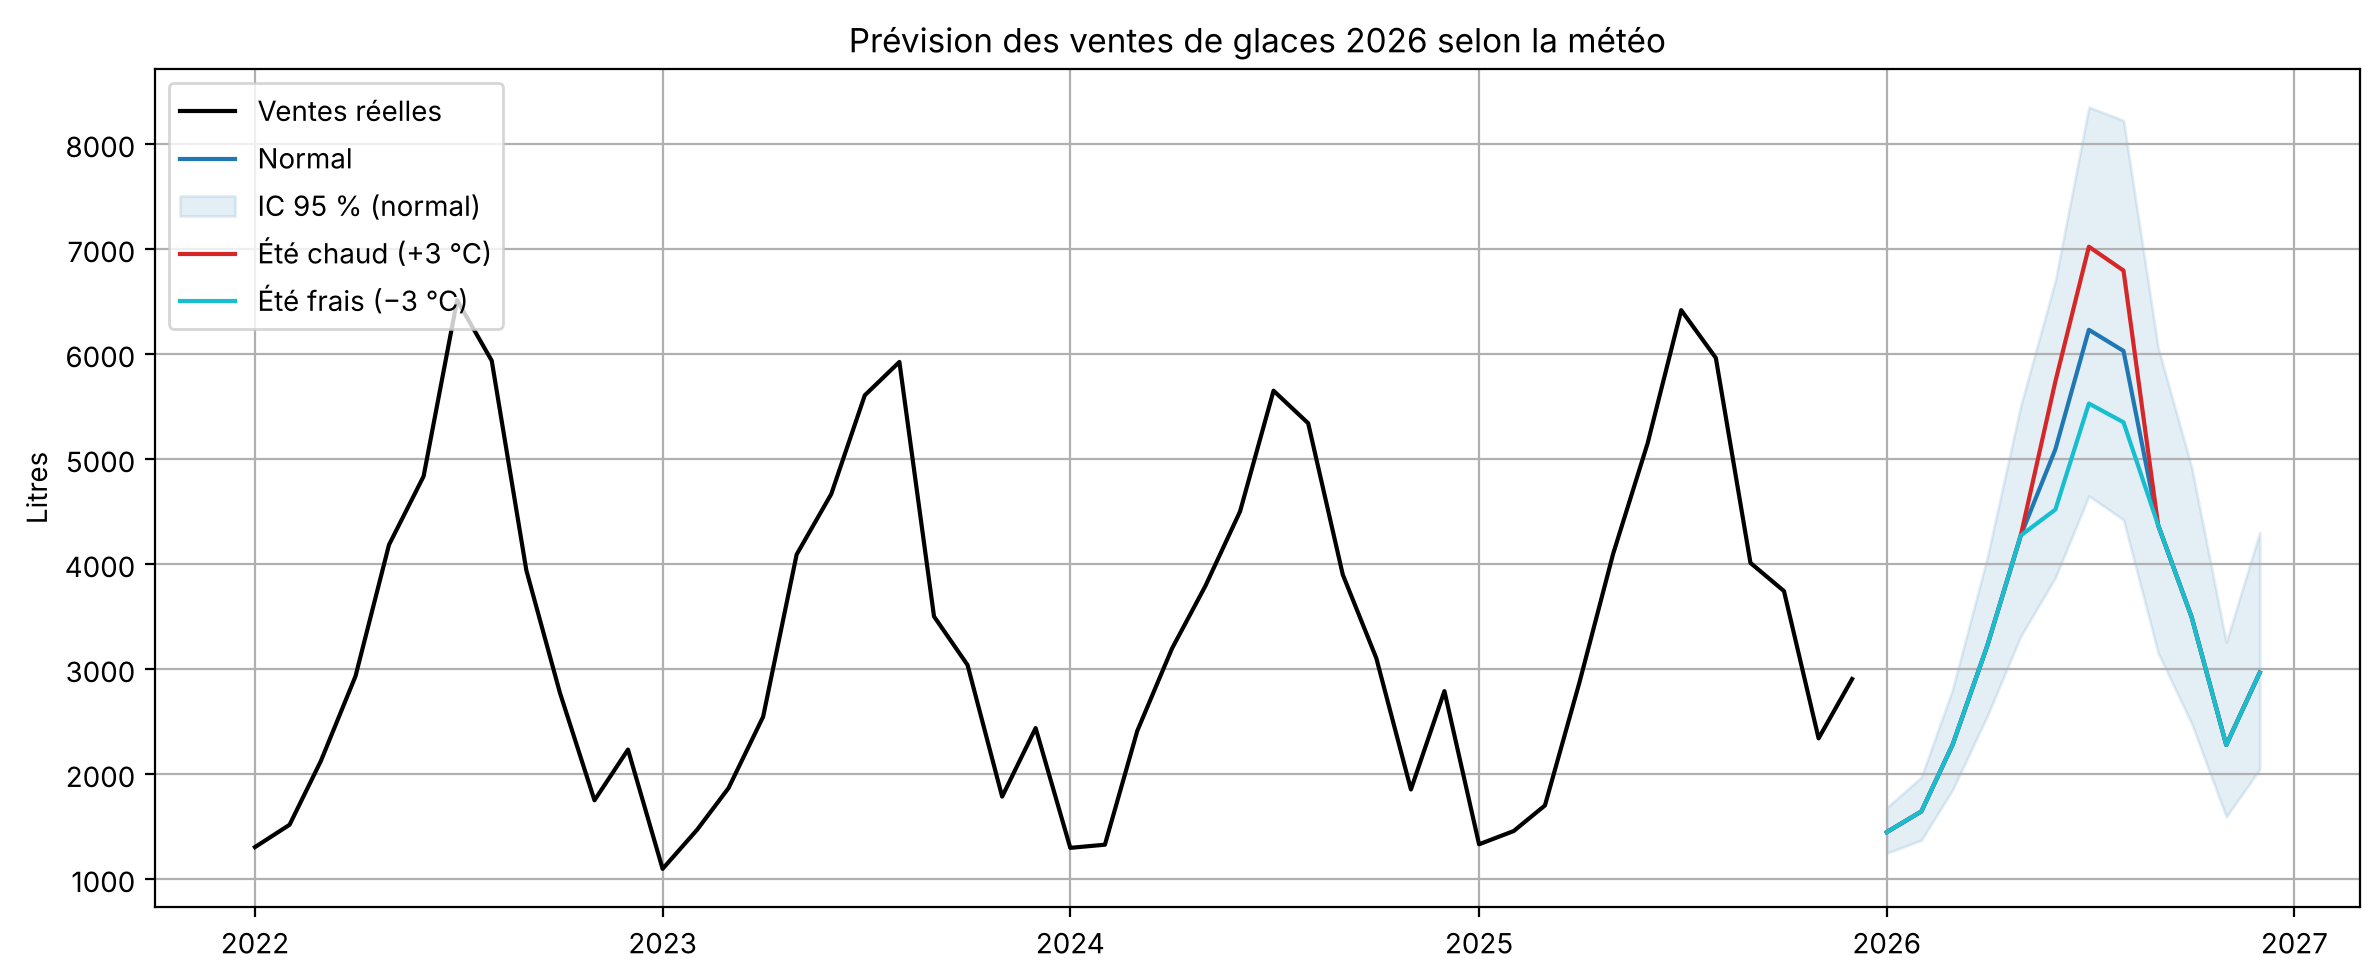

,Normal,Été chaud (+3 °C),Été frais (−3 °C)
Jan 2026,1442.0,1442.0,1442.0
Feb 2026,1639.0,1639.0,1639.0
Mar 2026,2275.0,2275.0,2275.0
Apr 2026,3216.0,3216.0,3216.0
May 2026,4267.0,4267.0,4267.0
Jun 2026,5088.0,5735.0,4514.0
Jul 2026,6226.0,7018.0,5524.0
Aug 2026,6025.0,6791.0,5345.0
Sep 2026,4366.0,4366.0,4366.0
Oct 2026,3490.0,3490.0,3490.0


Total annuel prévu (litres) :
Normal               43266.0
Été chaud (+3 °C)    45470.0
Été frais (−3 °C)    41310.0


In [ ]:
final = SARIMAX(data["log_ventes"], exog=data[["temperature_moy"]],
                order=ORDER, seasonal_order=SEASONAL).fit(disp=False)

futur = pd.date_range("2026-01-01", periods=12, freq="MS")
normale = data["temperature_moy"].groupby(data.index.month).mean()
temp_normale = pd.DataFrame({"temperature_moy": normale.loc[futur.month].values}, index=futur)
ete = futur.month.isin([6, 7, 8])

scenarios = {"Normal": temp_normale.copy(),
             "Été chaud (+3 °C)": temp_normale.assign(temperature_moy=temp_normale["temperature_moy"] + 3 * ete),
             "Été frais (−3 °C)": temp_normale.assign(temperature_moy=temp_normale["temperature_moy"] - 3 * ete)}

resultats = {}
plt.figure(figsize=(12, 5))
plt.plot(data["ventes_litres"]["2022":], color="black", label="Ventes réelles")
for (nom, X), coul in zip(scenarios.items(), ["tab:blue", "tab:red", "tab:cyan"]):
    f = final.get_forecast(12, exog=X)
    resultats[nom] = np.exp(f.predicted_mean)
    plt.plot(resultats[nom], color=coul, label=nom)
    if nom == "Normal":
        ci = np.exp(f.conf_int())
        plt.fill_between(futur, ci.iloc[:, 0], ci.iloc[:, 1], color=coul, alpha=0.12, label="IC 95 % (normal)")
plt.title("Prévision des ventes de glaces 2026 selon la météo")
plt.ylabel("Litres"); plt.legend(loc="upper left"); plt.tight_layout(); plt.show()

tableau = pd.DataFrame(resultats).round(0)
tableau.index = tableau.index.strftime("%b %Y")
display(tableau)
print("Total annuel prévu (litres) :")
print(pd.DataFrame(resultats).sum().round(0).to_string())

## 9. Conclusion

1. Les ventes de glaces sont **saisonnières, en croissance**, avec une amplitude qui augmente → modèle sur log(ventes), SARIMA(0,1,1)(0,1,1)[12].
2. Ajouter la **température** comme variable exogène améliore nettement le modèle (AIC plus bas, MAPE plus faible sur 2024-2025) et réduit l'incertitude des prévisions.
3. **+1 °C ≈ +4 % de ventes**, à saison et tendance égales. La **pluie** n'apporte rien de plus une fois la température prise en compte.
4. Limite : pour prévoir le futur, il faut une prévision de la température. Le modèle sert donc surtout à **simuler des scénarios** (été chaud / frais) pour ajuster stocks et production.